<a href="https://colab.research.google.com/github/iamrahul00007/Semantic-Search-with-ChromaDB/blob/main/VectorDB_performance_with_ChromaDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google import genai
from google.genai import types
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
from IPython.display import display

## Import the API_KEY...

In [ ]:
from google.colab import userdata

api_key = userdata.get('GEMINI_API_KEY')

if not api_key :
  raise RuntimeError("Google API not found!!")

client = genai.Client(api_key = api_key)

## Generate the Embeddings

In [ ]:
texts = [
    "How do I write the python code?",
    "How do I write the Java application code?",
    "Which smartphone has the best camera?",
    "Turn off the Camera.",
    "Switch the lights off.",
    "Apple released a new phone.",
    "Mango is my favourite fruit."
]

result = client.models.embed_content(
    model = "gemini-embedding-001",
    contents = texts,
    config = types.EmbedContentConfig(task_type ="SEMANTIC_SIMILARITY", outputDimensionality= 768)
)

for text, embedding_obj in zip(texts, result.embeddings):
    embedding = embedding_obj.values
    print("Text:" ,text)
    print("Embedding length:" , len(embedding))
    print("Embeddings:" , embedding)
    print("-"*70)

Text: How do I write the python code?
Embedding length: 768
Embeddings: [-0.0034725512, -0.0025407388, 0.013053155, -0.05025423, -0.01732143, -0.029915215, -0.013774865, 0.009608506, 0.037776973, 0.003907622, -0.018227722, -0.018627523, -0.017397402, 0.026455346, 0.12817237, 0.00035110122, -0.017495088, 0.006113317, -0.0003179355, -0.0074709305, -0.0036357609, 0.023375865, 0.01369406, -0.0321868, -0.0076876, -0.020238739, 0.021580312, 0.021953268, 0.039958015, -0.016129797, -0.0001524345, 0.015696343, -0.0016790585, 0.009486095, -0.003382684, 0.0007324278, 0.02293754, 0.015454391, 0.0072734854, 0.0354523, -0.013308772, 0.009579334, 0.010590579, 0.0009541601, 0.022849455, 0.021385109, -0.00846641, -0.03474924, -0.0037395342, 0.00910431, -0.012218057, -0.0029826204, -0.015107066, -0.17098562, 0.015360884, -0.0019280375, -0.0039572674, -0.00022165864, 0.0040466147, -0.0023822186, -0.023937786, 0.03389394, -0.033466145, -0.023236677, -0.0011304124, -0.01355071, 0.030352447, -0.01714233, 0.

## Create a 3x3 table to show the similarity matrix

In [ ]:
df = pd.DataFrame(
    cosine_similarity([e.values for e in result.embeddings]),
    index = texts,
    columns = texts
)
display(df)


,How do I write the python code?,How do I write the Java application code?,Which smartphone has the best camera?,Turn off the Camera.,Switch the lights off.,Apple released a new phone.,Mango is my favourite fruit.
How do I write the python code?,1.000000,0.874262,0.708994,0.700162,0.680988,0.712532,0.678124
How do I write the Java application code?,0.874262,1.000000,0.705930,0.683691,0.675110,0.694494,0.678305
Which smartphone has the best camera?,0.708994,0.705930,1.000000,0.747769,0.655075,0.793799,0.671018
Turn off the Camera.,0.700162,0.683691,0.747769,1.000000,0.875101,0.699920,0.632966
Switch the lights off.,0.680988,0.675110,0.655075,0.875101,1.000000,0.669857,0.624454
Apple released a new phone.,0.712532,0.694494,0.793799,0.699920,0.669857,1.000000,0.700898
Mango is my favourite fruit.,0.678124,0.678305,0.671018,0.632966,0.624454,0.700898,1.000000


## Reduce the Dimentionality with PCA

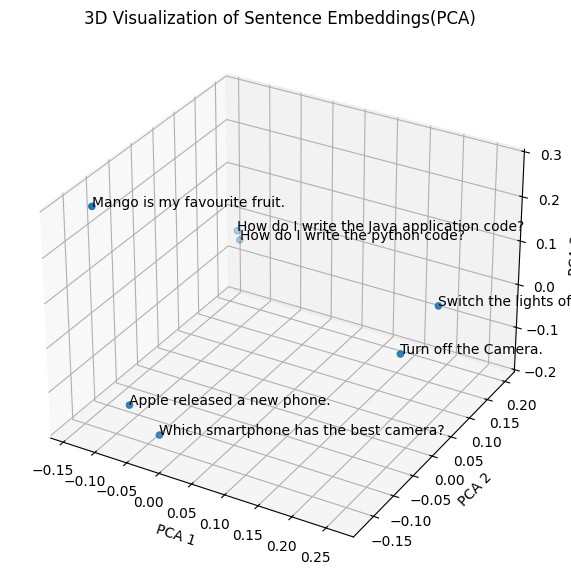

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

embeddings = np.array([e.values for e in result.embeddings])
pca = PCA(n_components=3)
reduced = pca.fit_transform(embeddings)

df = pd.DataFrame(reduced, columns = ["x", "y", "z"])
df["text"] = texts

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(df["x"], df["y"], df["z"])

for i, txt in enumerate(df["text"]):
    ax.text(df["x"][i], df["y"][i], df["z"][i], txt)
ax.set_title("3D Visualization of Sentence Embeddings(PCA)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")

plt.show()

## Responsive Visualization


In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='x',
    y='y',
    z='z',
    text='text',
    title='3D Embedding Visualization',
    height = 800,
    width = 1200
)

fig.show()

In [ ]:
pip install chromadb

## Store the Embeddings into the ChromaDB

In [ ]:
import chromadb
from chromadb.config import Settings

# Create ChromaDB client(local persistent DB)
chroma_client = chromadb.Client(
    Settings(
        persist_directory = './chroma_db'
    )
)
# Create a ChromaDB collection
collection = chroma_client.get_or_create_collection(
    name = 'chroma-db-demo'
)

# Extract embeddings
embeddings = []
ids = []

for i, embedding_obj in enumerate(result.embeddings):
  embeddings.append(embedding_obj.values)
  ids.append(f"id_{i}")

# Store in chroma
collection.add(
    ids=ids,
    documents = texts,
    embeddings = embeddings
)

print("Embeddings stored successfully!!")

Embeddings stored successfully!!


In [ ]:
try:
    # Delete the collection to clear out duplicate entries
    chroma_client.delete_collection('chroma-db-demo')
    print("Previous collection deleted successfully!")
except Exception as e:
    print("No existing collection to delete:", e)

# Re-create a clean collection
collection = chroma_client.get_or_create_collection(
    name = 'chroma-db-demo'
)

# Store the embeddings only once
collection.add(
    ids=ids,
    documents=texts,
    embeddings=embeddings
)
print("Clean embeddings stored successfully!")

Previous collection deleted successfully!
Clean embeddings stored successfully!


## Query Embeddings in ChromaDB

In [ ]:
query = "programming"

# Generate the query_embedding using the same embedding model and dimensions.
query_embedding = client.models.embed_content(
    model = 'gemini-embedding-001',
    contents = [query],
    config = types.EmbedContentConfig(
        task_type = "SEMANTIC_SIMILARITY",
        outputDimensionality = 768
    )
).embeddings[0].values

results = collection.query(
    query_embeddings = [query_embedding],
    n_results = 2
)
print(results['documents'])

[['How do I write the python code?', 'How do I write the Java application code?']]
